# 02 · Triangles and diagnostics

**Question this notebook answers:** before projecting anything, is there evidence that the past is *not* a good guide to the future?

The chain ladder assumes each accident year will develop like the average of earlier years. That fails when something changes along a **calendar** dimension, such as a faster claims department, a change in case reserving philosophy, or a jump in inflation, because those affect every accident year at once from a point in time. The diagnostics here look for that.

All figures are USD 000, net of reinsurance, as known at 31/12/1997.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.diagnostics import ratio_triangle, diagonal_shift, pearson_residuals, residuals_by
from reserving.factors import average_factors, cdfs
from reserving.methods import chain_ladder
from reserving import backtest as B

df = D.load_cas()
co = D.company(df, cfg.STUDY_GRCODE)
universe = D.backtest_universe(df)
ind = D.industry(df, exclude=cfg.STUDY_GRCODE, grcodes=universe)
paid, case = co.paid, co.case

## 1. The triangles

**Paid** = cumulative payments. **Case incurred** = payments + case reserves set by claims handlers on known claims (Schedule P incurred *minus* the company's bulk/IBNR, so it holds no actuarial IBNR).

In [3]:
print("Cumulative paid (USD 000)")
paid.values.style.format("{:,.0f}", na_rep="")

Cumulative paid (USD 000)


dev,1,2,3,4,5,6,7,8,9,10
origin,,,,,,,,,,
1988,"5,407","14,422","19,063","22,447","24,142","25,404","26,829","27,202","27,443","27,449"
1989,"6,279","15,031","21,203","25,697","27,807","28,726","29,173","29,375","29,444",
1990,"7,256","15,923","20,701","24,963","27,847","29,274","30,163","30,656",,
1991,"5,028","10,345","15,042","18,837","21,708","22,808","23,465",,,
1992,"5,712","11,809","18,198","22,000","26,306","27,168",,,,
1993,"7,413","16,798","24,570","30,420","33,803",,,,,
1994,"10,868","23,205","31,171","39,702",,,,,,
1995,"10,143","24,336","32,406",,,,,,,
1996,"9,596","21,831",,,,,,,,


In [4]:
print("Cumulative case incurred (USD 000)")
case.values.style.format("{:,.0f}", na_rep="")

Cumulative case incurred (USD 000)


dev,1,2,3,4,5,6,7,8,9,10
origin,,,,,,,,,,
1988,"15,198","23,838","25,764","26,309","26,445","27,453","27,327","27,508","27,560","27,568"
1989,"16,272","25,369","29,158","30,233","29,566","29,314","29,434","29,684","29,619",
1990,"19,043","25,714","28,266","29,486","30,467","30,579","30,633","30,743",,
1991,"12,698","19,216","21,103","22,443","24,546","24,017","24,176",,,
1992,"15,609","22,512","24,912","26,626","27,447","27,612",,,,
1993,"17,509","25,652","31,528","34,360","35,987",,,,,
1994,"22,786","34,345","40,686","44,210",,,,,,
1995,"24,703","37,300","40,550",,,,,,,
1996,"23,707","32,432",,,,,,,,


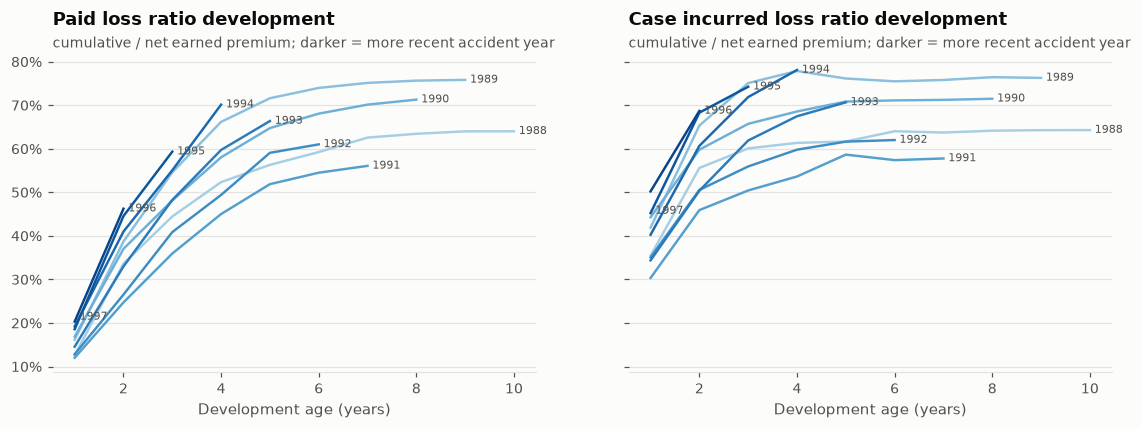

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
cmap = plt.get_cmap("Blues")
for ax, tri, title in [(axes[0], paid, "Paid"), (axes[1], case, "Case incurred")]:
    for i, o in enumerate(tri.origins):
        row = tri.values.loc[o].dropna() / co.premium[o]
        ax.plot(row.index, row.values, color=cmap(0.35 + 0.65 * i / (len(tri.origins) - 1)), lw=1.6)
        ax.text(row.index[-1] + 0.1, row.values[-1], str(o), fontsize=7, color=PL.INK_2, va="center")
    ax.set_title(f"{title} loss ratio development")
    PL.subtitle(ax, "cumulative / net earned premium; darker = more recent accident year")
    ax.set_xlabel("Development age (years)")
    PL.pct(ax)
fig.tight_layout()
PL.save(fig, "02_development_by_ay")
plt.show()

Case incurred reaches its plateau by about age 4, while paid is still climbing at age 7. That's normal for liability lines: claims handlers reserve known claims early, but payment takes years. It also means **case incurred contains far more information about recent years than paid does**. Using the selected factors (notebook 03), only about **20%** of the ultimate is paid by age 1, against about **55%** case-reported.

The more recent (darker) curves sit higher on both charts, consistent with the rising loss ratios seen in notebook 01.

## 2. Paid-to-case ratios: has anything changed?

If the claims process is stable, the ratio of paid to case incurred at a given age should be roughly the same for every accident year. **Movement down the diagonals** says something changed at a point in calendar time.

In [6]:
pc = ratio_triangle(paid, case)
pc.style.format("{:.3f}", na_rep="").background_gradient(axis=0, cmap="Blues")

dev,1,2,3,4,5,6,7,8,9,10
origin,,,,,,,,,,
1988,0.356,0.605,0.740,0.853,0.913,0.925,0.982,0.989,0.996,0.996
1989,0.386,0.592,0.727,0.850,0.941,0.980,0.991,0.990,0.994,
1990,0.381,0.619,0.732,0.847,0.914,0.957,0.985,0.997,,
1991,0.396,0.538,0.713,0.839,0.884,0.950,0.971,,,
1992,0.366,0.525,0.730,0.826,0.958,0.984,,,,
1993,0.423,0.655,0.779,0.885,0.939,,,,,
1994,0.477,0.676,0.766,0.898,,,,,,
1995,0.411,0.652,0.799,,,,,,,
1996,0.405,0.673,,,,,,,,


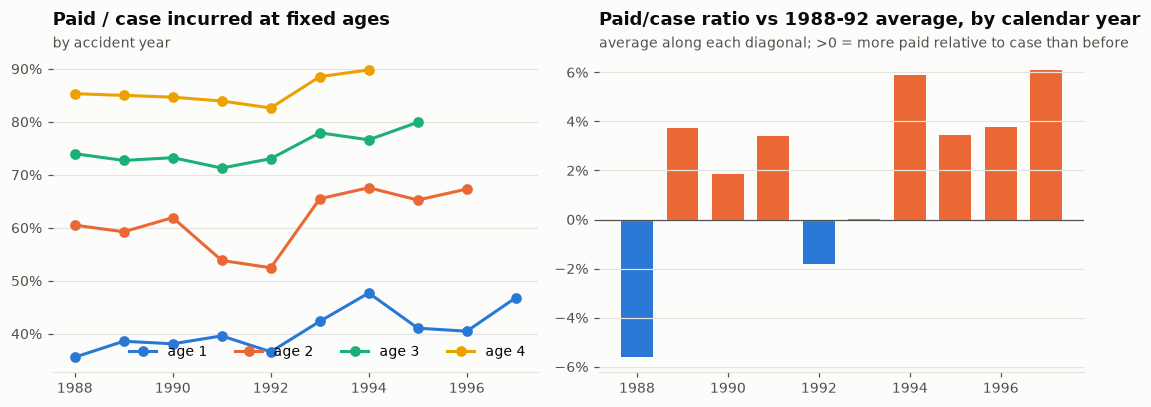

In [7]:
shift = diagonal_shift(pc, base_origins=5)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for age, col in zip([1, 2, 3, 4], PL.SERIES):
    s = pc[age].dropna()
    ax.plot(s.index, s.values, marker="o", color=col, label=f"age {age}")
ax.set_title("Paid / case incurred at fixed ages")
PL.subtitle(ax, "by accident year")
PL.pct(ax)
ax.legend(ncol=4, loc="lower right")
ax = axes[1]
ax.bar(shift.index.astype(int), shift.values - 1, color=[PL.SERIES[1] if v > 1 else PL.SERIES[0] for v in shift.values], width=0.7)
ax.axhline(0, color=PL.INK_2, lw=0.8)
ax.set_title("Paid/case ratio vs 1988-92 average, by calendar year")
PL.subtitle(ax, "average along each diagonal; >0 = more paid relative to case than before")
PL.pct(ax)
fig.tight_layout()
PL.save(fig, "02_paid_to_case")
plt.show()

**Finding:** from the 1993 accident year onwards, paid/case ratios at ages 1-4 are clearly higher than for 1988-92. At age 1 they average ~0.44 against ~0.38, and at age 2 ~0.66 against ~0.58. Along the diagonals the ratio runs about 3-6% above its earlier level in every calendar year from 1994.

There are two classic explanations, and they point in **opposite directions** for the reserve:

| Hypothesis | What it means | Effect on paid CL | Effect on case CL |
|---|---|---|---|
| **A. Faster settlement** | claims are being paid more quickly | paid factors from older (slower) years are too high → **paid CL overstates** | unaffected |
| **B. Weaker case reserves** | claims handlers now reserve less per claim | unaffected | case factors from older (stronger) years are too low → **case CL understates** |

Berquist & Sherman (1977) adjust for each using **claim counts**: closed-to-reported ratios test for (A), average case reserve per open claim tests for (B). Schedule P Part 1 has no counts, so **this question cannot be fully resolved here**. In a real review this is the first information request I would send to the claims team. Notebook 07 shows these exact count-based diagnostics on claim-level data.

What *can* be checked: hypothesis B predicts **higher case development at early ages for recent years**. The case link ratios (notebook 03) show 1993 and 1994 at age 2→3 well above earlier years (1.23 and 1.19 vs ~1.10), which is mild support for B. The paid link ratios for recent years at ages 1-2 aren't obviously lower, which would be the signature of A. So the evidence is mixed. That supports **not relying on either basis alone**, and the selection in notebook 08 takes this into account.

## 3. Calendar-year effects: residuals

The over-dispersed Poisson (ODP) model behind the chain ladder (Renshaw & Verrall, 1998) gives fitted incremental amounts. Pearson residuals averaged **by calendar year** should scatter around zero; a run of positives or negatives points to a calendar effect such as inflation.

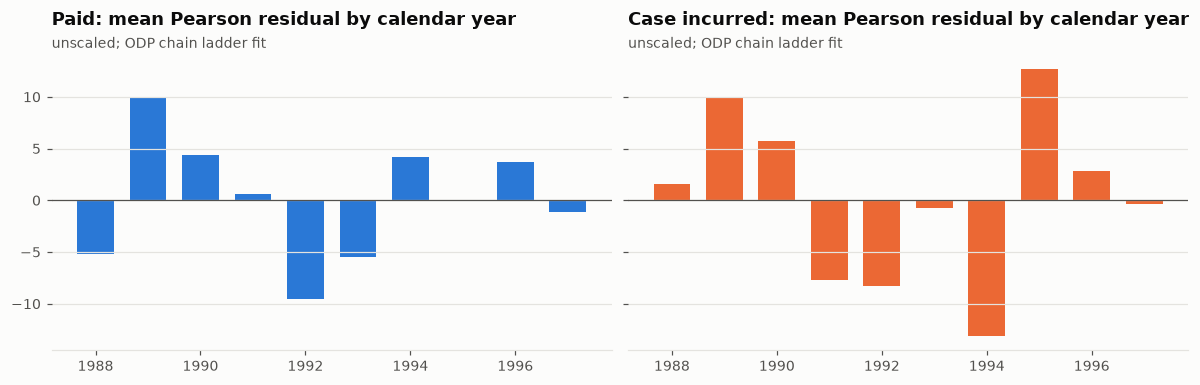

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, tri, name, col in [(axes[0], paid, "Paid", PL.SERIES[0]), (axes[1], case, "Case incurred", PL.SERIES[1])]:
    r = residuals_by(pearson_residuals(tri), "calendar")["mean"]
    ax.bar(r.index.astype(int), r.values, color=col, width=0.7)
    ax.axhline(0, color=PL.INK_2, lw=0.8)
    ax.set_title(f"{name}: mean Pearson residual by calendar year")
    PL.subtitle(ax, "unscaled; ODP chain ladder fit")
fig.tight_layout()
PL.save(fig, "02_calendar_residuals")
plt.show()

No sustained calendar trend in either basis. The residuals alternate in sign (1989-90 positive, 1992-93 negative, mixed afterwards), which looks like noise rather than an inflation shift. So I don't make an explicit inflation adjustment for this company. Claims inflation in mid-1990s US commercial auto was moderate and broadly stable, so it is already embedded in the historical factors. (Contrast notebook 07, where an inflation shock is clearly visible.)

## 4. Loss ratio drift: company vs industry

The company's loss ratios matter for the BF prior. Here are the **chain ladder (case incurred)** loss ratios rather than the company's own reported figures, so they are not influenced by the IBNR the company chose to hold:

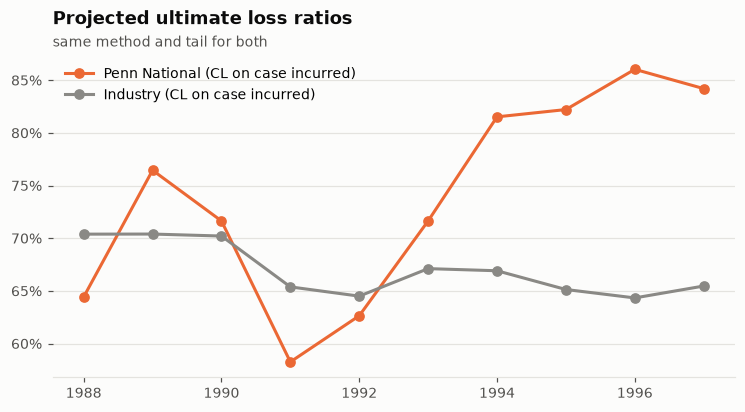

origin,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997
Penn National,64.4%,76.5%,71.6%,58.3%,62.6%,71.6%,81.5%,82.2%,86.0%,84.2%
Industry,70.4%,70.4%,70.2%,65.4%,64.5%,67.1%,66.9%,65.1%,64.3%,65.5%
Difference,-6.0%,6.1%,1.4%,-7.1%,-1.9%,4.5%,14.6%,17.1%,21.7%,18.7%


In [9]:
c_case = cdfs(average_factors(case), cfg.TAIL_CASE)
co_lr = chain_ladder(case, c_case)["ultimate"] / co.premium
ind_lr = B.industry_prior_lr(ind.case, ind.premium)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(co_lr.index, co_lr, marker="o", color=PL.SERIES[1], label="Penn National (CL on case incurred)")
ax.plot(ind_lr.index, ind_lr, marker="o", color=PL.NEUTRAL, label="Industry (CL on case incurred)")
ax.set_title("Projected ultimate loss ratios")
PL.subtitle(ax, "same method and tail for both")
PL.pct(ax)
ax.legend()
PL.save(fig, "02_lr_vs_industry")
plt.show()
pd.DataFrame({"Penn National": co_lr, "Industry": ind_lr, "Difference": co_lr - ind_lr}).T.style.format("{:.1%}")

On a like-for-like projection, Penn National was **better than the industry for 1988-92** (~66% vs ~68%) but **much worse from 1994** (82-86% vs ~65%). This is a big, sustained gap, so a BF prior built from the industry loss ratio would understate the company's recent years. Notebook 04 builds the prior from the company's own experience instead.

## Conclusions → next steps

1. **Case incurred is the more informative basis** for recent years (≈55% reported at age 1 vs ≈20% paid).
2. **Paid/case ratios have risen since 1993.** Either settlement sped up (paid CL overstates) or case reserves weakened (case CL understates). Without claim counts this can't be resolved, so neither basis should be used alone.
3. **No calendar-year (inflation) trend** visible, so no explicit inflation adjustment.
4. **The company's loss ratio has moved above the industry's** since 1994, so an industry-based BF prior would be too low.